In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [ ]:
df = pd.read_excel('/content/online_retail_II.xlsx')

print(df.head())

  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   
3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

          InvoiceDate  Price  Customer ID         Country  
0 2009-12-01 07:45:00   6.95      13085.0  United Kingdom  
1 2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
2 2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
3 2009-12-01 07:45:00   2.10      13085.0  United Kingdom  
4 2009-12-01 07:45:00   1.25      13085.0  United Kingdom  


In [ ]:
df = df.dropna(subset=['Customer ID'])
df = df[df['Quantity'] > 0]
df = df[df['Price'] > 0]

In [ ]:
#rfm analysis
df['Amount'] = df['Quantity'] * df['Price']

today = df['InvoiceDate'].max()

rfm = df.groupby('Customer ID').agg({
    'InvoiceDate': lambda x: (today - x.max()).days,
    'Invoice': 'nunique',
    'Amount': 'sum'
})

rfm.columns = ['Recency', 'Frequency', 'Monetary']

print(rfm.head())

             Recency  Frequency  Monetary
Customer ID                              
12346.0          164         11    372.86
12347.0            2          2   1323.32
12348.0           73          1    222.16
12349.0           42          3   2671.14
12351.0           10          1    300.93


In [ ]:
#scaling
scaler = StandardScaler()
X = scaler.fit_transform(rfm)

In [ ]:
#k-means
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

rfm['KMeans'] = kmeans.fit_predict(X)

print(rfm.head())

             Recency  Frequency  Monetary  KMeans
Customer ID                                      
12346.0          164         11    372.86       1
12347.0            2          2   1323.32       0
12348.0           73          1    222.16       0
12349.0           42          3   2671.14       0
12351.0           10          1    300.93       0


In [ ]:
#dbscan
db = DBSCAN(eps=0.5, min_samples=5)

rfm['DBSCAN'] = db.fit_predict(X)

print(rfm.head())

             Recency  Frequency  Monetary  KMeans  DBSCAN
Customer ID                                              
12346.0          164         11    372.86       1       0
12347.0            2          2   1323.32       0       0
12348.0           73          1    222.16       0       0
12349.0           42          3   2671.14       0       0
12351.0           10          1    300.93       0       0


In [ ]:
#pca
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

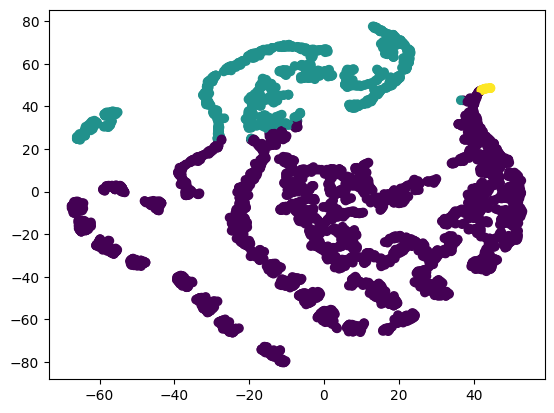

In [ ]:
#tsne
tsne = TSNE(n_components=2, random_state=42)

X_tsne = tsne.fit_transform(X_pca)

plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=rfm['KMeans'])
plt.show()

In [ ]:
#marketing personas
print(rfm.groupby('KMeans')[['Recency', 'Frequency', 'Monetary']].mean())

           Recency   Frequency       Monetary
KMeans                                       
0        41.264279    4.942575    2082.315956
1       240.683019    1.654717     594.019655
2         3.230769  111.538462  112132.389231
